# Buchstaben erkennen: CNN versus MLP
**Deep Learning für Computer Vision – Notebook 05**

Wir erzeugen eigene Bilder und verfolgen den gesamten Weg vom Datensatz bis zur
Verwechslungsmatrix. Jedes Bild enthält genau einen Großbuchstaben **A–Z** mit
zufälliger Schriftgröße, Position und Rotation zwischen **−45° und +45°**.

1. **Datensatz erzeugen:** PNG-Bilder mit 200 × 200 Pixeln in `train/` und `test/`.
2. **CNN trainieren:** Trainings-/Validierungssplit, Lernkurven und Pickle-Datei.
3. **CNN testen:** Modell laden, Accuracy, Verwechslungsmatrix und Fehlbeispiele.
4. **MLP vergleichen:** dieselben Eingaben und Splits, aber keine Conv-/Pool-Layer.

**Lernziele:** lokale Merkmale, geteilte Gewichte und Pooling verstehen; Overfitting
an Lernkurven erkennen; Validierung von einem unabhängigen Abschlusstest unterscheiden.

Für Datengenerierung und Training die Zellen von oben nach unten ausführen.
**Abschnitt 3 ist anschließend auch nach einem Kernel-Neustart allein ausführbar.** Die Standardkonfiguration ist ein Lehrversuch;
insbesondere auf einer CPU kann das Training mehrere Minuten dauern. Für einen
Technikcheck zunächst kleinere Bildzahlen und eine Epoche wählen. Solche Miniläufe
liefern noch keinen belastbaren Architekturvergleich.


## Vorbereitung
Benötigt werden `torch`, `torchvision`, `numpy`, `Pillow` und `matplotlib`. Falls nötig, die folgende
Installationszeile aktivieren und danach den Kernel neu starten. Eine GPU ist optional.
`torchvision` übernimmt das Einlesen der Bildordner und die Vorverarbeitung.


In [3]:
# %pip install torch torchvision numpy pillow matplotlib

from pathlib import Path
import copy
import hashlib
import json
import pickle
import random
import string
import time

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Verhindert auf großen CPU-Systemen unnötig viele konkurrierende Threads.
torch.set_num_threads(min(4, torch.get_num_threads()))
print("PyTorch:", torch.__version__, "| Gerät:", DEVICE)


PyTorch: 2.9.1+cu128 | Gerät: cuda


In [ ]:
DEVICE

## 1. Einen eigenen Buchstabendatensatz erzeugen

Die Variablen `N_TRAIN` und `N_TEST` geben jeweils die **Gesamtzahl** der Bilder an.
Die Klassen werden möglichst gleich häufig erzeugt (Unterschied höchstens ein Bild).
Trainings- und Testbilder verwenden getrennte Zufallszahlengeneratoren.

Eine einzelne Schriftart hält den Versuch übersichtlich: Wir untersuchen geometrische
Variation, noch keine Generalisierung auf andere Schriftarten oder Handschrift.
Alle Buchstaben bleiben vollständig im Bild. Wir drehen zuerst den freigestellten
Buchstaben und wählen danach eine passende Position auf der Zeichenfläche.


In [4]:
26*400

10400

In [6]:
# ---------- Zentrale Einstellungen ----------
N_TRAIN = 10_400           # insgesamt, also 400 Bilder pro Buchstabe
N_TEST = 2_600             # insgesamt, also 100 Bilder pro Buchstabe
IMAGE_SIZE = 200           # gespeicherte PNGs: immer 200 × 200
FONT_SIZE_MIN = 48
FONT_SIZE_MAX = 140
MAX_ROTATION = 45.0
CLASSES = list(string.ascii_uppercase)
DATA_ROOT = Path("buchstaben_daten")
MODEL_PATH = Path("cnn_buchstaben.pkl")

# Optional einen eigenen TrueType-/OpenType-Font angeben, z. B. unter Windows.
FONT_PATH = None
font_candidates = [
    FONT_PATH,
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    "C:/Windows/Fonts/arial.ttf",
    "/System/Library/Fonts/Supplemental/Arial.ttf",
    "DejaVuSans.ttf",
]
for candidate in font_candidates:
    if candidate is None:
        continue
    try:
        font_probe = ImageFont.truetype(str(candidate), 64)
        FONT_PATH = str(font_probe.path)
        break
    except OSError:
        pass
else:
    raise FileNotFoundError("Bitte FONT_PATH auf eine vorhandene .ttf-Datei setzen.")

assert N_TRAIN >= 2 * len(CLASSES), "Mindestens zwei Trainingsbilder pro Klasse nötig."
assert N_TEST >= len(CLASSES), "Mindestens ein Testbild pro Klasse nötig."
print("Schrift:", FONT_PATH)
print("Datenordner:", DATA_ROOT.resolve())


Schrift: /usr/share/fonts/truetype/dejavu/DejaVuSans.ttf
Datenordner: /media/veracrypt1/07_src/examples/066_ws26_deep_learning_for_computer_vision/buchstaben_daten


In [7]:
def render_letter(letter, rng):
    font_size = rng.randint(FONT_SIZE_MIN, FONT_SIZE_MAX)
    angle = rng.uniform(-MAX_ROTATION, MAX_ROTATION)
    font = ImageFont.truetype(FONT_PATH, font_size)
    left, top, right, bottom = font.getbbox(letter)
    # Kleine Sicherheitsränder verhindern Abschneiden beim Rendern.
    glyph = Image.new("L", (right - left + 8, bottom - top + 8), 0)
    ImageDraw.Draw(glyph).text((4 - left, 4 - top), letter, font=font, fill=255)
    glyph = glyph.rotate(angle, resample=Image.Resampling.BICUBIC, expand=True)
    bbox = glyph.getbbox()
    if bbox is None:
        raise ValueError(f"Leeres Zeichen: {letter}")
    glyph = glyph.crop(bbox)
    width, height = glyph.size
    if width > IMAGE_SIZE or height > IMAGE_SIZE:
        raise ValueError("Schrift zu groß: FONT_SIZE_MAX verringern.")
    x = rng.randint(0, IMAGE_SIZE - width)
    y = rng.randint(0, IMAGE_SIZE - height)
    canvas = Image.new("L", (IMAGE_SIZE, IMAGE_SIZE), 255)
    canvas.paste(Image.new("L", glyph.size, 0), (x, y), glyph)
    return canvas


def generate_split(directory, count, seed):
    rng = random.Random(seed)
    labels = [CLASSES[i % len(CLASSES)] for i in range(count)]
    rng.shuffle(labels)
    for label in CLASSES:
        (directory / label).mkdir(parents=True, exist_ok=True)
    for index, letter in enumerate(labels):
        render_letter(letter, rng).save(directory / letter / f"{index:06d}.png")


# Ein Manifest macht wiederholtes Ausführen sicher und nachvollziehbar.
# Bestehende Daten werden nur bei exakt passender Konfiguration wiederverwendet.
generation_config = {
    "version": 1, "n_train": N_TRAIN, "n_test": N_TEST,
    "image_size": IMAGE_SIZE, "font_size_min": FONT_SIZE_MIN,
    "font_size_max": FONT_SIZE_MAX, "max_rotation": MAX_ROTATION,
    "font_sha256": hashlib.sha256(Path(FONT_PATH).read_bytes()).hexdigest(),
    "seed": SEED, "classes": CLASSES,
}
manifest_path = DATA_ROOT / "manifest.json"
if DATA_ROOT.exists() and any(DATA_ROOT.iterdir()):
    if not manifest_path.exists():
        raise RuntimeError("Datenordner ist nicht leer und hat kein Manifest. Neues DATA_ROOT wählen.")
    if json.loads(manifest_path.read_text()) != generation_config:
        raise RuntimeError("Konfiguration geändert. Bitte ein neues DATA_ROOT wählen.")
    print("Passenden vorhandenen Datensatz wiederverwenden.")
else:
    generate_split(DATA_ROOT / "train", N_TRAIN, SEED)
    generate_split(DATA_ROOT / "test", N_TEST, SEED + 1)
    manifest_path.write_text(json.dumps(generation_config, indent=2), encoding="utf-8")
    print("Datensatz erzeugt.")

for split, expected in [("train", N_TRAIN), ("test", N_TEST)]:
    paths = sorted((DATA_ROOT / split).glob("*/*.png"))
    assert len(paths) == expected, f"Unvollständiger Datensatz: {split}"
    counts = [len(list((DATA_ROOT / split / c).glob("*.png"))) for c in CLASSES]
    assert max(counts) - min(counts) <= 1 and sum(counts) == expected
    print(f"{split}: {len(paths):,} PNGs, {min(counts)}–{max(counts)} je Klasse")


Passenden vorhandenen Datensatz wiederverwenden.
train: 10,400 PNGs, 400–400 je Klasse
test: 2,600 PNGs, 100–100 je Klasse


Die Ordnerstruktur ist `buchstaben_daten/train/A/*.png` bis `train/Z/*.png` und
entsprechend `test/A/*.png` bis `test/Z/*.png`. Die Ordnernamen liefern die Labels.
Bei geänderten Erzeugungsparametern bitte einen neuen `DATA_ROOT` wählen. Das
Notebook löscht keine bestehenden Daten und mischt keine alten Bilder hinzu.


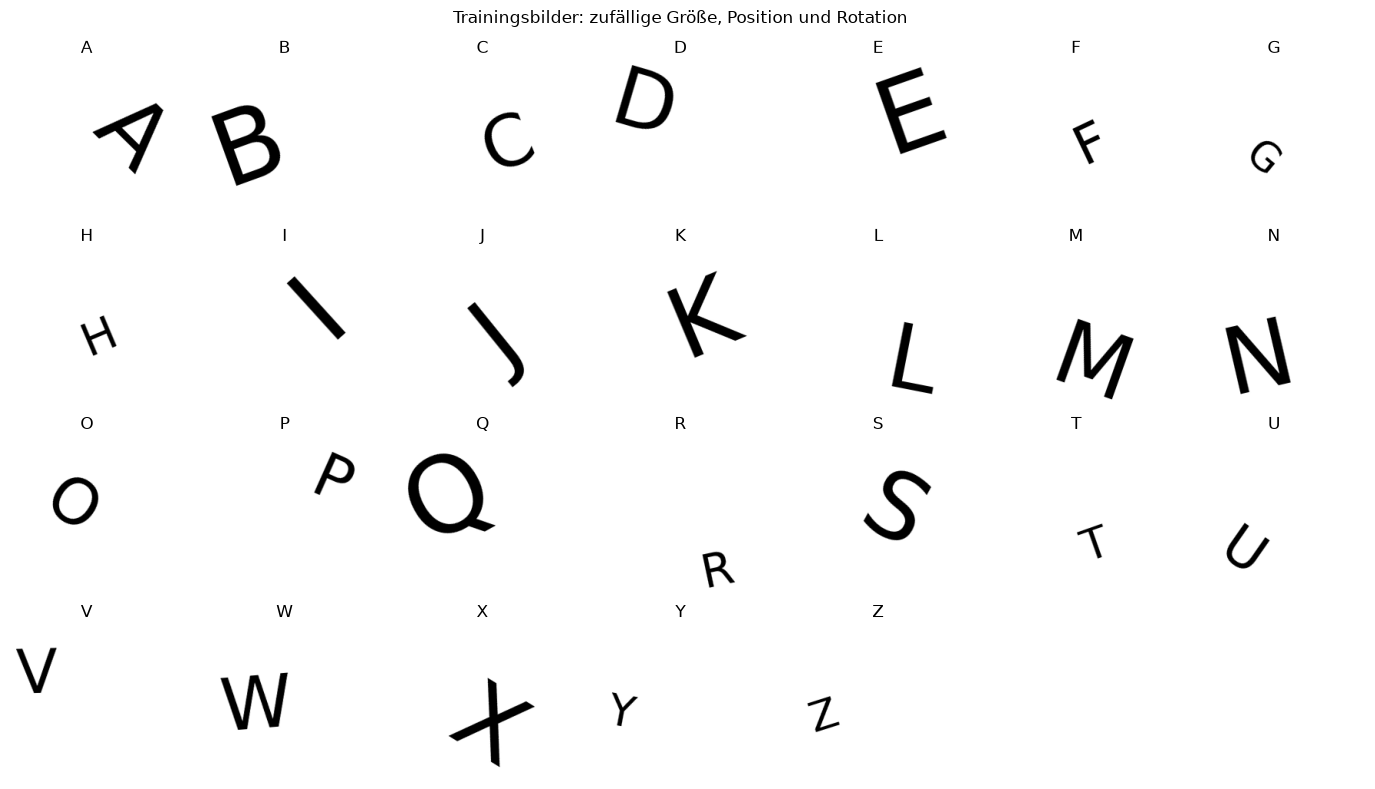

In [8]:
# Vorschau ausschließlich aus dem Trainingsordner: Der Test bleibt bis Abschnitt 3 zu.
fig, axes = plt.subplots(4, 7, figsize=(14, 8))
preview_rng = random.Random(SEED)
for index, ax in enumerate(axes.flat):
    ax.axis("off")
    if index < len(CLASSES):
        letter = CLASSES[index]
        path = preview_rng.choice(sorted((DATA_ROOT / "train" / letter).glob("*.png")))
        with Image.open(path) as im:
            ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(letter)
plt.suptitle("Trainingsbilder: zufällige Größe, Position und Rotation")
plt.tight_layout()
plt.show()


In [9]:
CLASSES

['A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'J',
 'K',
 'L',
 'M',
 'N',
 'O',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'U',
 'V',
 'W',
 'X',
 'Y',
 'Z']

## 2. Ein CNN in PyTorch erstellen und trainieren

20 % der Bilder aus `train/` dienen zur **Validierung**; der Rest aktualisiert die
Gewichte. `random_split` teilt die Bilder einmal zufällig auf; beide Modelle verwenden
anschließend genau dieselbe Aufteilung. Die Klassenanteile können dabei leicht schwanken.
`test/` wird weder für die Modellauswahl noch zum Abstimmen von Hyperparametern verwendet.

Die Vorverarbeitung verkleinert jedes Bild auf 64 × 64 und kehrt die Helligkeit um:
Hintergrund = 0, Buchstaben = 1. Beide Modelle bekommen dieselben Tensoren.

Unser CNN lernt mit 3 × 3-Filtern zunächst lokale Muster. Max-Pooling verringert die
räumliche Auflösung. Nach drei Blöcken verdichtet ein kleiner Klassifikator die Merkmale
zu 26 **Logits**. `CrossEntropyLoss` enthält bereits die nötige Log-Softmax-Operation;
im Modell steht deshalb kein Softmax.


### Bilder mit Standardbausteinen laden

Eine eigene Dataset-Klasse ist hier nicht nötig. `ImageFolder` erwartet genau unsere
Ordnerstruktur: **ein Unterordner pro Klasse**. Es liest die Bilder bei Bedarf ein
und vergibt die Labels alphabetisch: A = 0, B = 1, …, Z = 25.

Wir gehen in vier kleinen Schritten vor: Vorverarbeitung festlegen, den Bildordner
öffnen, Training und Validierung aufteilen und schließlich Batches bilden.

In [36]:
# Beide Netze erhalten dieselbe, auf 64 × 64 verkleinerte Version der PNGs.
# Das spart Rechenzeit; die Originalbilder auf der Festplatte bleiben 200 × 200.
INPUT_SIZE = 64
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
VAL_FRACTION = 0.20

In [37]:
# 1. Vorverarbeitung für jedes Bild
transform = transforms.Compose([
    transforms.Grayscale(),                     # ein Farbkanal
    transforms.Resize((INPUT_SIZE, INPUT_SIZE)), # 200 × 200 → 64 × 64
    transforms.ToTensor(),                      # Pixel 0–255 → Tensor mit Werten 0–1
    transforms.Lambda(transforms.functional.invert), # Hintergrund 0, Buchstabe 1
])

In [38]:
# 2. Trainingsdatensatz vorbereiten. Trainingsdatensatz ist ein Bildordner.
full_train = datasets.ImageFolder(DATA_ROOT / "train", transform=transform)
print("Klassen:", full_train.classes)
print("Anzahl Bilder:", len(full_train))

# Ein einzelner Eintrag besteht aus Bildtensor und Klassennummer.
image, label = full_train[0]
print("Bildform:", image.shape)     # [1, 64, 64]: Kanal, Höhe, Breite
print("Label:", label, "→", full_train.classes[label])

Klassen: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Anzahl Bilder: 10400
Bildform: torch.Size([1, 64, 64])
Label: 0 → A


In [39]:
full_train

Dataset ImageFolder
    Number of datapoints: 10400
    Root location: buchstaben_daten/train
    StandardTransform
Transform: Compose(
               Grayscale(num_output_channels=1)
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
               Lambda()
           )

In [40]:
len(full_train)

10400

`ImageFolder` übernimmt Dateisuche und Labelzuordnung; `transform` beschreibt die
Bildumwandlung. `ToTensor()` ergänzt auch die Kanalachse und normiert die Pixelwerte.
Die letzte Zeile der Vorverarbeitung kehrt hell und dunkel um. Dafür verwenden wir
die benannte Funktion `transforms.functional.invert`. Im Gegensatz zu einer anonymen
`lambda`-Funktion lässt sie sich zusammen mit der Vorverarbeitung per Pickle speichern.

Für die Validierung reservieren wir 20 % der Bilder. Der feste Seed sorgt dafür,
dass bei erneutem Ausführen dieselbe Aufteilung entsteht. Bei sehr kleinen
Datensätzen können einzelne Klassen im Validierungsteil fehlen.

In [41]:
VAL_FRACTION

0.2

In [42]:
# 3. Einmal in Trainings- und Validierungsdaten aufteilen
n_val = int(len(full_train) * VAL_FRACTION)
n_train = len(full_train) - n_val

train_data, val_data = random_split(
    full_train, [n_train, n_val],
    generator=torch.Generator().manual_seed(SEED),
)
print("Training:", len(train_data), "| Validierung:", len(val_data))

Training: 8320 | Validierung: 2080


In [43]:
type(train_data), type(val_data)

(torch.utils.data.dataset.Subset, torch.utils.data.dataset.Subset)

In [44]:
BATCH_SIZE

128

In [21]:
# 4. DataLoader liefern kleine Bildpakete (Batches).
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE)

xb, yb = next(iter(train_loader))
print("Bilder im Batch:", xb.shape)  # [Batchgröße, 1, 64, 64]
print("Labels im Batch:", yb.shape)  # [Batchgröße]
print("Korrektklassifikationsrate beim zufälligen Raten ca.", f"{1 / len(CLASSES):.2%}")

Bilder im Batch: torch.Size([128, 1, 64, 64])
Labels im Batch: torch.Size([128])
Korrektklassifikationsrate beim zufälligen Raten ca. 3.85%


In [45]:
for images, labels in train_loader:
    print(images.shape)
    print(labels.shape)
    break

torch.Size([128, 1, 64, 64])
torch.Size([128])


In [46]:
# Sequential führt die Layer in der angegebenen Reihenfolge aus.
# Alle Layer sind PyTorch-Standardklassen: keine eigene Modellklasse nötig.
set_seed(SEED)
cnn = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),                    # 64x64 → 32x32
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),                    # 32x32 → 16x16
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),                    # 16x16 → 8x8
    nn.AdaptiveAvgPool2d((4, 4)),        # 8x8 → 4x4
    nn.Flatten(),
    nn.Linear(64 * 4*4, 128),
    nn.ReLU(),
    nn.Dropout(0.25),
    nn.Linear(128, len(CLASSES)),
).to(DEVICE)


def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(cnn)
print(f"Trainierbare Parameter: {parameter_count(cnn):,}")
with torch.no_grad():
    print("Ausgabeform:", tuple(cnn(xb.to(DEVICE)).shape))


Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): AdaptiveAvgPool2d(output_size=(4, 4))
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Linear(in_features=1024, out_features=128, bias=True)
  (12): ReLU()
  (13): Dropout(p=0.25, inplace=False)
  (14): Linear(in_features=128, out_features=26, bias=True)
)
Trainierbare Parameter: 157,850
Ausgabeform: (128, 26)


### Gemeinsame Trainingsroutine

Wir messen Loss und Accuracy pro Epoche. Die Trainingswerte entstehen während der
Gewichtsaktualisierung (inklusive Dropout), die Validierungswerte danach in `eval()`.
Gespeichert wird der Zustand mit dem **kleinsten Validierungs-Loss**.
Dasselbe Auswahlkriterium gilt später für das MLP. Die Testdaten bleiben unberührt.


Wir trennen **Lernen** und **Bewerten** in zwei Funktionen. So ist sichtbar,
welche drei Befehle nur beim Lernen vorkommen: `zero_grad()`, `backward()` und `step()`.
Beide Funktionen liefern den mittleren Loss und den Anteil richtiger Vorhersagen.

In [47]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Vorwärtsrechnung: Vorhersage und Fehler berechnen
        logits = model(images)
        loss = nn.functional.cross_entropy(logits, labels)

        # Lernen: alte Gradienten löschen, neue berechnen, Gewichte anpassen
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += len(labels)

    return loss_sum / total, correct / total

In [32]:
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0

    # Beim Bewerten werden keine Gradienten und keine Gewichtsänderungen benötigt.
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)

            loss_sum += loss.item() * len(labels)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += len(labels)

    return loss_sum / total, correct / total

`fit` wiederholt diese beiden Schritte für mehrere Epochen und sammelt die
Lernkurven. `deepcopy` merkt sich eine unabhängige Kopie der bisher besten Gewichte;
sonst würden weitere Trainingsschritte auch den gemerkten Zustand verändern.

In [48]:
EPOCHS = 60
EPOCHS

60

In [49]:
def fit(model, name):
    # Jeder Trainingslauf startet mit derselben Batch-Reihenfolge.
    train_loader = DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)
    history = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best_loss, best_state, best_epoch = float("inf"), None, None
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate(model, val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
        print(f"{name} {epoch:02d}/{EPOCHS}: "
              f"Loss {train_loss:.3f}/{val_loss:.3f} | "
              f"Accuracy Train {train_acc:.1%}, Val {val_acc:.1%}")
    model.load_state_dict(best_state)
    model.eval()
    elapsed = time.perf_counter() - started
    print(f"{name}: beste Epoche {best_epoch}, Trainingszeit {elapsed:.1f} s")
    return history, best_epoch, elapsed


In [50]:
set_seed(SEED)
cnn_history, cnn_best_epoch, cnn_seconds = fit(cnn, "CNN")

CNN 01/60: Loss 3.248/3.227 | Accuracy Train 4.4%, Val 5.1%
CNN 02/60: Loss 3.145/3.078 | Accuracy Train 7.4%, Val 9.6%
CNN 03/60: Loss 2.878/2.610 | Accuracy Train 12.6%, Val 17.2%
CNN 04/60: Loss 2.432/2.200 | Accuracy Train 20.0%, Val 28.1%
CNN 05/60: Loss 2.092/1.863 | Accuracy Train 29.5%, Val 39.3%
CNN 06/60: Loss 1.796/1.569 | Accuracy Train 39.0%, Val 50.8%
CNN 07/60: Loss 1.602/1.373 | Accuracy Train 45.1%, Val 55.6%
CNN 08/60: Loss 1.410/1.233 | Accuracy Train 51.2%, Val 59.9%
CNN 09/60: Loss 1.285/1.093 | Accuracy Train 54.9%, Val 65.6%
CNN 10/60: Loss 1.180/1.008 | Accuracy Train 58.9%, Val 67.8%
CNN 11/60: Loss 1.074/0.907 | Accuracy Train 62.3%, Val 71.0%
CNN 12/60: Loss 1.029/0.852 | Accuracy Train 63.9%, Val 73.1%
CNN 13/60: Loss 0.950/0.807 | Accuracy Train 66.3%, Val 73.8%
CNN 14/60: Loss 0.943/0.732 | Accuracy Train 67.1%, Val 76.5%
CNN 15/60: Loss 0.821/0.724 | Accuracy Train 70.8%, Val 77.3%
CNN 16/60: Loss 0.773/0.664 | Accuracy Train 72.6%, Val 78.0%
CNN 17/60: L

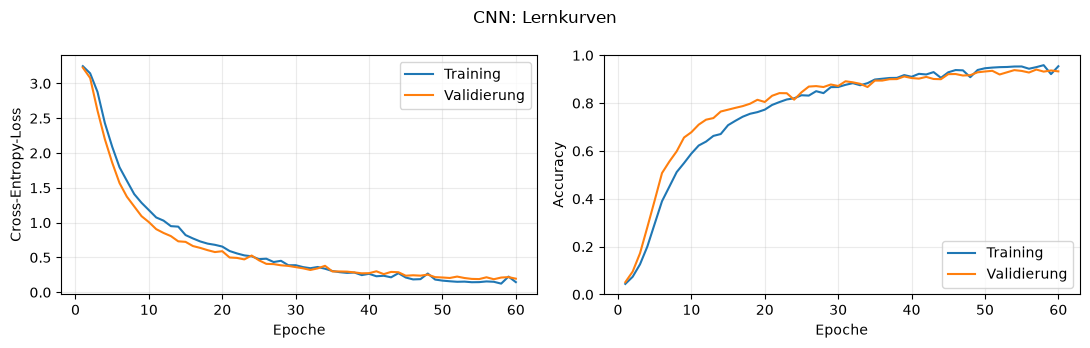

In [51]:
def plot_history(history, title):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for split, label in [("train", "Training"), ("val", "Validierung")]:
        axes[0].plot(epochs, history[f"{split}_loss"], label=label)
        axes[1].plot(epochs, history[f"{split}_acc"], label=label)
    axes[0].set_ylabel("Cross-Entropy-Loss")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0, 1)
    for ax in axes:
        ax.set_xlabel("Epoche")
        ax.legend()
        ax.grid(alpha=0.25)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(cnn_history, "CNN: Lernkurven")


### Modell und Vorverarbeitung zusammen speichern

Für eine Vorhersage brauchen wir drei Dinge: **das trainierte Netz, die Vorverarbeitung der Bilder
und die Reihenfolge der Klassen**. Ein PyTorch-Modell ist ein Python-Objekt; wir hängen
die beiden Zusatzinformationen einfach als Attribute daran und pickeln dann das ganze
Objekt. Ein zusätzliches Dictionary ist nicht nötig.

Das Netz besteht ausschließlich aus PyTorch-Standard-Layern in `nn.Sequential`.
Auch die Transforms verwenden Standardbausteine und eine benannte Funktion. Dadurch
brauchen wir zum Laden keine zuvor ausgeführte eigene Klassen- oder Funktionsdefinition.
Die benötigten Bibliotheken müssen weiterhin installiert sein.

Vor dem Speichern verschieben wir das Modell auf die CPU, damit es auch ohne GPU
wieder eingelesen werden kann. Nach dieser Änderung die Speicherzelle erneut ausführen;
alte Pickle-Dateien enthalten die neuen Attribute noch nicht.

**Nur eigene oder vertrauenswürdige Pickle-Dateien laden:** `pickle.load` kann Code ausführen.

In [52]:
# Die für Vorhersagen nötigen Informationen direkt am Modell mitnehmen.
cnn.transform = transform
cnn.classes = full_train.classes

cnn.cpu()
with MODEL_PATH.open("wb") as file:
    pickle.dump(cnn, file)

print("Modell inklusive Vorverarbeitung und Klassen gespeichert:", MODEL_PATH)

Modell inklusive Vorverarbeitung und Klassen gespeichert: cnn_buchstaben.pkl


## 3. Das gespeicherte CNN laden und auf Testbildern prüfen

**Dieser Abschnitt ist nach einem Kernel-Neustart allein ausführbar.** Er benötigt nur
die bereits erzeugte Pickle-Datei, die Testbilder und die installierten Bibliotheken.
Alle Imports und Auswertungsfunktionen stehen hier; Code aus Abschnitt 1 oder 2 muss
nicht erneut ausgeführt werden.

Das geladene Modell bringt seine **Gewichte, Vorverarbeitung und Klassenreihenfolge**
mit. Modellpfad und Testordner stellen wir in der nächsten Zelle ein. Die relativen
Pfade beziehen sich auf das Arbeitsverzeichnis des Kernels; absolute Pfade sind ebenfalls möglich.

Accuracy ist der Anteil korrekt klassifizierter Testbilder. In der Verwechslungsmatrix
steht die **wahre Klasse in der Zeile**, die **Vorhersage in der Spalte**.
Die normierte Darstellung zeigt Anteile innerhalb der jeweiligen wahren Klasse.

In [53]:
# Alle Imports für diesen Abschnitt – auch nach einem Kernel-Neustart.
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision import datasets

# Hier die Pfade zur gespeicherten Datei und zu den Testbildern einstellen.
TEST_MODEL_PATH = Path("cnn_buchstaben.pkl")
TEST_DIR = Path("buchstaben_daten/test")
TEST_BATCH_SIZE = 128
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [54]:
DEVICE

device(type='cuda')

In [55]:
# Nur eine eigene oder vertrauenswürdige Pickle-Datei laden.
with TEST_MODEL_PATH.open("rb") as file:
    cnn_loaded = pickle.load(file)

cnn_loaded.to(DEVICE)
cnn_loaded.eval()

# Diese Informationen kommen aus der Datei, nicht aus vorherigen Zellen.
transform = cnn_loaded.transform
CLASSES = cnn_loaded.classes

print("Klassen:", CLASSES)
print("Vorverarbeitung:", transform)

Klassen: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Vorverarbeitung: Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Lambda()
)


In [56]:
test_data = datasets.ImageFolder(TEST_DIR, transform=transform)
# Ordnernamen müssen zu den gespeicherten Ausgabeklassen passen.
assert test_data.classes == CLASSES, "Testordner und Modell haben unterschiedliche Klassen."
print("Testbilder:", len(test_data))

Testbilder: 2600


Die folgenden Funktionen sammeln Vorhersagen und zeichnen die Verwechslungsmatrix.
Sie sind hier vollständig definiert und verwenden keine Trainingsdaten.

In [58]:
def predict(model, dataset):
    loader = DataLoader(dataset, batch_size=TEST_BATCH_SIZE, shuffle=False, num_workers=0)
    true, predicted = [], []
    model.eval()
    with torch.inference_mode():
        for images, labels in loader:
            logits = model(images.to(DEVICE))
            true.append(labels.numpy())
            predicted.append(logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(true), np.concatenate(predicted)


def confusion_matrix(y_true, y_pred, n_classes):
    matrix = np.zeros((n_classes, n_classes), dtype=np.int64)
    for true_label, predicted_label in zip(y_true, y_pred):
        matrix[true_label, predicted_label] += 1
    return matrix


def show_confusion(matrix, classes, title):
    normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
    fig, axes = plt.subplots(1, 2, figsize=(17, 7))
    for ax, values, subtitle, fmt in [
        (axes[0], matrix, "Anzahl", "d"),
        (axes[1], normalized, "Anteil je wahrer Klasse", ".2f"),
    ]:
        im = ax.imshow(values, cmap="Blues", vmin=0,
                       vmax=1 if fmt == ".2f" else max(1, matrix.max()))
        for row, col in zip(*np.nonzero(matrix)):
            value = values[row, col]
            ax.text(col, row, format(value, fmt), ha="center", va="center", fontsize=6,
                    color="white" if value > im.norm.vmax / 2 else "black")
        ax.set_xticks(range(len(classes)), classes, fontsize=8)
        ax.set_yticks(range(len(classes)), classes, fontsize=8)
        ax.set_xlabel("Vorhergesagte Klasse")
        ax.set_ylabel("Wahre Klasse")
        ax.set_title(subtitle)
        fig.colorbar(im, ax=ax, shrink=0.75)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

CNN-Test-Accuracy: 93.46% (2430/2600)


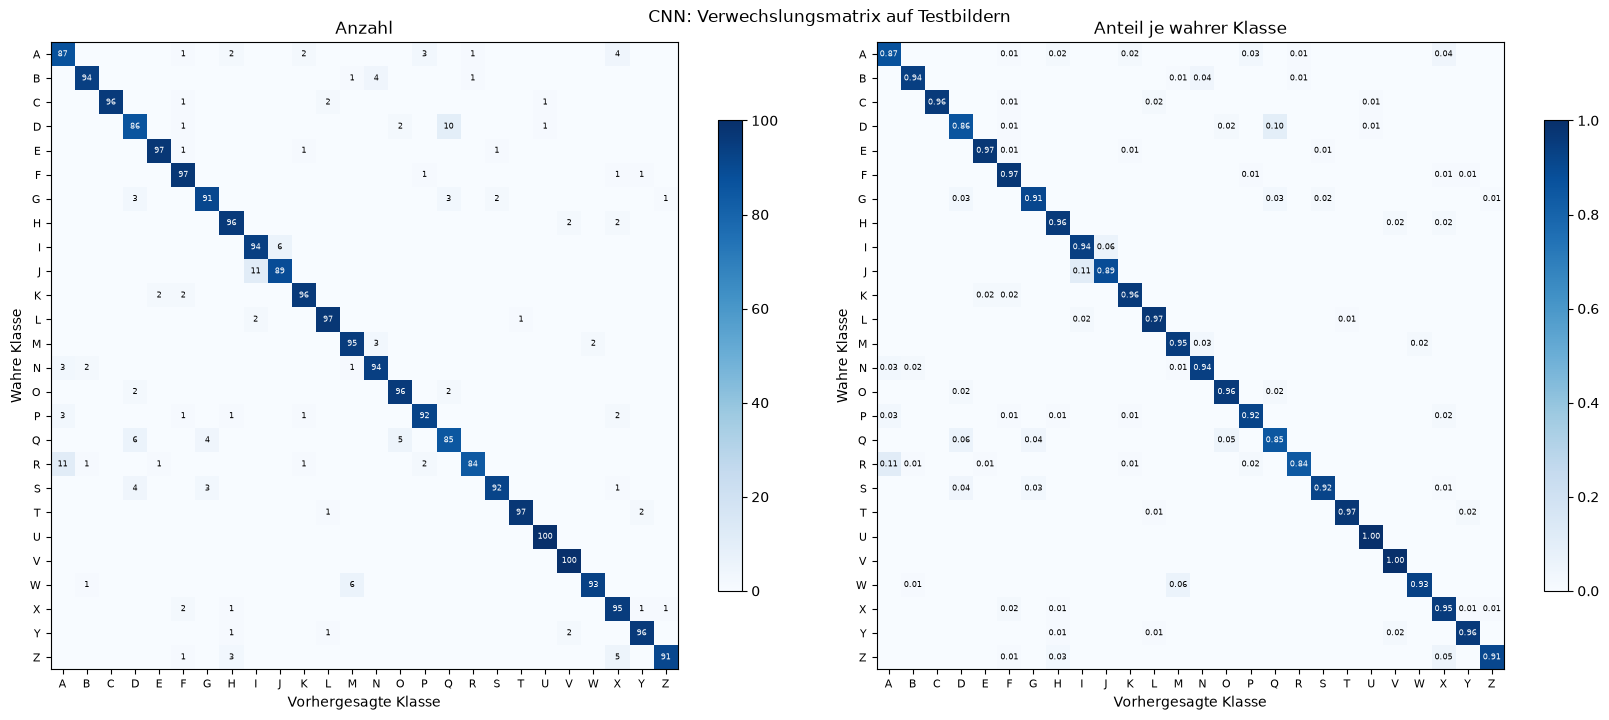

In [59]:
cnn_true, cnn_pred = predict(cnn_loaded, test_data)
cnn_matrix = confusion_matrix(cnn_true, cnn_pred, len(CLASSES))
cnn_accuracy = float((cnn_true == cnn_pred).mean())
assert cnn_matrix.sum() == len(test_data)
print(f"CNN-Test-Accuracy: {cnn_accuracy:.2%} ({np.trace(cnn_matrix)}/{len(test_data)})")
show_confusion(cnn_matrix, CLASSES, "CNN: Verwechslungsmatrix auf Testbildern")

## 4. Warum ein MLP bei variabler Bildgeometrie Schwierigkeiten hat

Das MLP flacht die 64 × 64 Pixel zu 4096 Eingaben ab. Es besitzt zwei versteckte
Schichten, aber **keine Convolution und kein Pooling**. Ein Strich an Position (10, 10)
und derselbe Strich an (40, 40) treffen auf andere Eingangsgewichte. Im CNN wird derselbe
Filter an allen Positionen angewendet; Max-Pooling reduziert die Empfindlichkeit gegenüber
kleinen Verschiebungen. Weder Rotation noch Skalierung werden dadurch automatisch invariant.

**Wissenschaftlich fair bleiben:** Ein ausreichend großes MLP kann diese Aufgabe ebenfalls
lernen. Ein garantiertes „Versagen“ lässt sich nicht seriös versprechen. Wir prüfen die
Hypothese, dass das MLP bei begrenzter Datenmenge und gleichem Trainingsbudget schlechter
generalisiert. Wir schwächen es dafür nicht künstlich durch andere Daten oder weniger Epochen.

Beide Netze bekommen dieselben Bilder, dieselbe Vorverarbeitung, denselben Train-/Val-Split,
dieselbe Batch-Reihenfolge, dieselbe Epochenzahl, denselben Optimierer und dasselbe
Auswahlkriterium. Das MLP erhält sogar mehr Parameter. Gleiche Epochen bedeuten gleiche
Datenkontakte, aber weder gleiche Rechenzeit noch eine für jede Architektur optimale Lernrate.


CNN: 157,850 Parameter
MLP: 1,085,082 Parameter
MLP 01/60: Loss 3.232/3.197 | Accuracy Train 4.3%, Val 5.2%
MLP 02/60: Loss 3.086/3.038 | Accuracy Train 9.6%, Val 9.1%
MLP 03/60: Loss 2.855/2.873 | Accuracy Train 14.7%, Val 12.9%
MLP 04/60: Loss 2.592/2.726 | Accuracy Train 21.5%, Val 18.3%
MLP 05/60: Loss 2.341/2.609 | Accuracy Train 28.1%, Val 19.2%
MLP 06/60: Loss 2.127/2.542 | Accuracy Train 34.7%, Val 21.8%
MLP 07/60: Loss 1.930/2.553 | Accuracy Train 39.1%, Val 22.2%
MLP 08/60: Loss 1.764/2.500 | Accuracy Train 43.5%, Val 24.7%
MLP 09/60: Loss 1.594/2.506 | Accuracy Train 49.5%, Val 25.1%
MLP 10/60: Loss 1.455/2.510 | Accuracy Train 54.1%, Val 25.4%
MLP 11/60: Loss 1.349/2.542 | Accuracy Train 56.9%, Val 26.8%
MLP 12/60: Loss 1.225/2.595 | Accuracy Train 60.8%, Val 25.9%
MLP 13/60: Loss 1.128/2.651 | Accuracy Train 63.7%, Val 26.2%
MLP 14/60: Loss 1.055/2.673 | Accuracy Train 66.0%, Val 27.3%
MLP 15/60: Loss 0.958/2.748 | Accuracy Train 69.8%, Val 27.5%
MLP 16/60: Loss 0.895/2.82

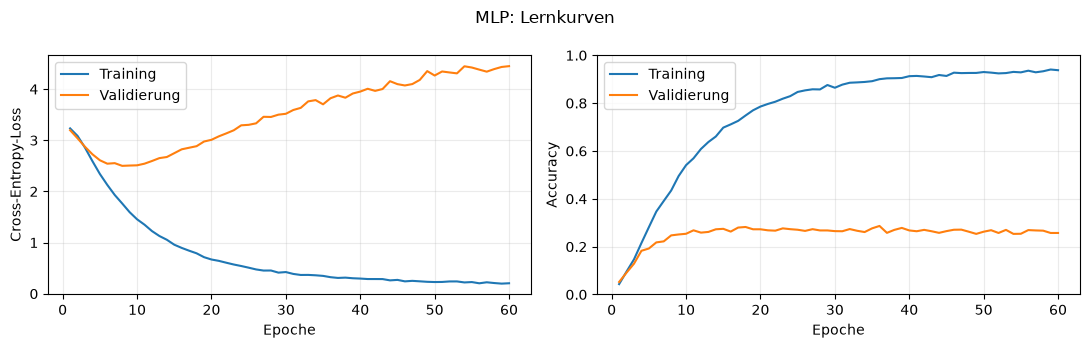

In [60]:
class LetterMLP(nn.Module):
    def __init__(self, input_size, n_classes=26):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_size * input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.net(x)


set_seed(SEED)
mlp = LetterMLP(INPUT_SIZE, len(CLASSES)).to(DEVICE)
print(f"CNN: {parameter_count(cnn):,} Parameter")
print(f"MLP: {parameter_count(mlp):,} Parameter")
# Initialisierung und stochastisches Training wie beim CNN getrennt setzen.
set_seed(SEED)
mlp_history, mlp_best_epoch, mlp_seconds = fit(mlp, "MLP")
plot_history(mlp_history, "MLP: Lernkurven")
